# TUGAS DATA MINING: VISUALISASI DATA
# Dataset Keaktifan Pemuda Karang Taruna

# Import Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Menghubungkan Google Colab dengan Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Membaca dataset dari Google Drive

In [6]:
file_path = '/content/drive/MyDrive/Data Mining/Data Visualization Elen/Data_Hasil_Cleansing_Elen_100_Baris.xlsx'

df = pd.read_excel(file_path, engine='openpyxl')

print("Dataset berhasil dibaca!")
print("Jumlah baris dan kolom:", df.shape)
display(df.head())

Dataset berhasil dibaca!
Jumlah baris dan kolom: (100, 10)


,ID Anggota,Nama,Usia,Jenis Kelamin,Dusun,Kehadiran Kegiatan,Frekuensi Kegiatan,Status Keaktifan,Jumlah Kegiatan,No HP
0,KT-00001,Andi Pratama,21,Laki-laki,Krajan,90.0,8,Aktif,8,8.123457e+10
1,KT-0002,Budi Santoso,22,Laki-laki,Krajan,85.0,7,Aktif,7,8.214568e+10
2,KT-00003,Siti Aminah,20,Perempuan,Krajan,75.0,6,Aktif,6,8.123457e+10
3,KT-00004,Rina Wulandari,19,Perempuan,Barat,60.0,5,Cukup Aktif,5,8.389989e+10
4,KT-00005,Dimas Saputra,23,Laki-laki,Barat,95.0,9,Aktif,9,8.123457e+10


# MEMERIKSA DATA

In [7]:
print("\nJumlah data kosong:")
print(df.isnull().sum())

print("\nJumlah data duplikat:")
print(df.duplicated().sum())


Jumlah data kosong:
ID Anggota            0
Nama                  0
Usia                  0
Jenis Kelamin         0
Dusun                 0
Kehadiran Kegiatan    0
Frekuensi Kegiatan    0
Status Keaktifan      0
Jumlah Kegiatan       0
No HP                 3
dtype: int64

Jumlah data duplikat:
0


# MENAMBAHKAN KOLOM KELOMPOK USIA

In [8]:
df["Kelompok Usia"] = pd.cut(
    df["Usia"],
    bins=[0, 17, 25, 35, 100],
    labels=["Di bawah 18", "18-25", "26-35", "Di atas 35"]
)

print("\nDistribusi kelompok usia:")
print(df["Kelompok Usia"].value_counts().sort_index())


Distribusi kelompok usia:
Kelompok Usia
Di bawah 18     6
18-25          73
26-35          21
Di atas 35      0
Name: count, dtype: int64


# AGREGASI DATA STATUS KEAKTIFAN

In [9]:
status = df["Status Keaktifan"].value_counts()

print("\nJumlah anggota berdasarkan status:")
print(status)



Jumlah anggota berdasarkan status:
Status Keaktifan
Aktif          45
Cukup Aktif    28
Tidak Aktif    27
Name: count, dtype: int64


# VISUALISASI 1 : STATUS KEAKTIFAN

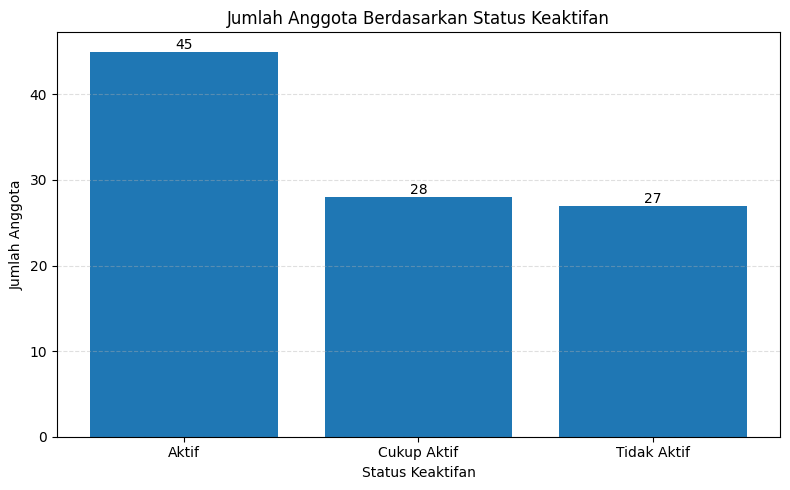

In [10]:
plt.figure(figsize=(8, 5))
bars = plt.bar(status.index, status.values)

plt.title("Jumlah Anggota Berdasarkan Status Keaktifan")
plt.xlabel("Status Keaktifan")
plt.ylabel("Jumlah Anggota")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        int(bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# VISUALISASI 2 : JENIS KELAMIN

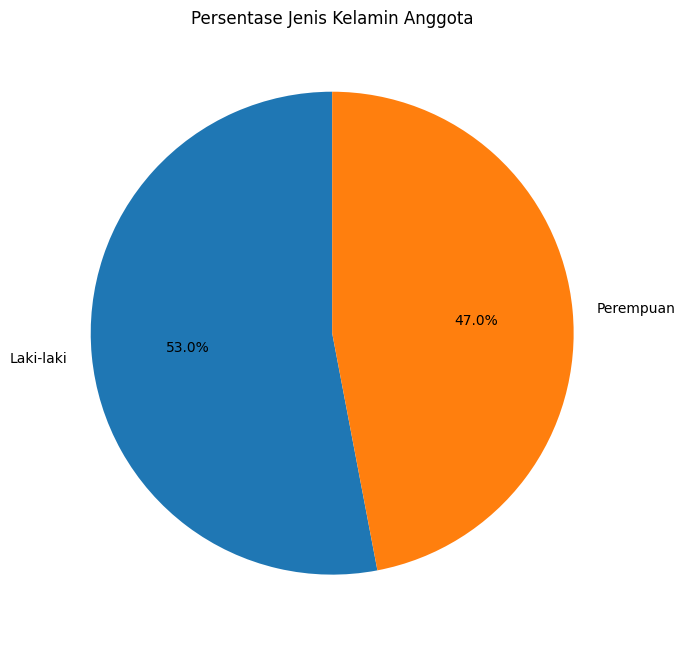

In [11]:
gender = df["Jenis Kelamin"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    gender.values,
    labels=gender.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Persentase Jenis Kelamin Anggota")
plt.tight_layout()
plt.show()


# VISUALISASI 3: HISTOGRAM USIA

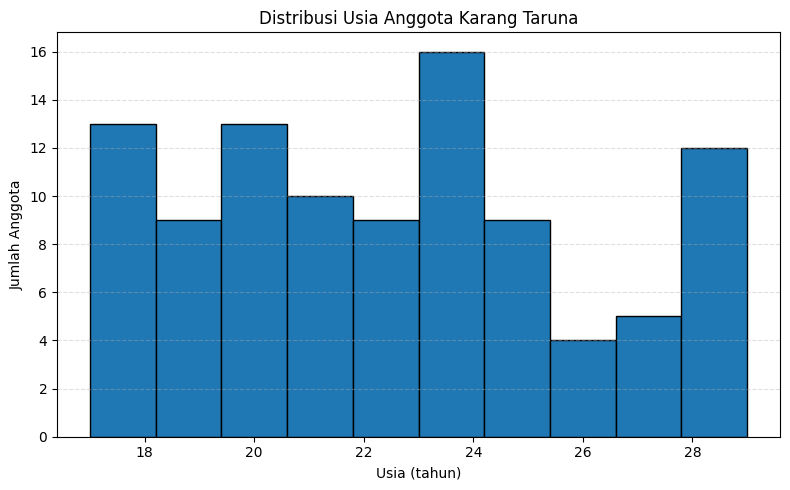

In [12]:
plt.figure(figsize=(8, 5))
plt.hist(df["Usia"], bins=10, edgecolor="black")

plt.title("Distribusi Usia Anggota Karang Taruna")
plt.xlabel("Usia (tahun)")
plt.ylabel("Jumlah Anggota")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# AGREGASI RATA-RATA KEHADIRAN PER DUSUN

In [13]:
kehadiran_dusun = (
    df.groupby("Dusun")["Kehadiran Kegiatan"]
    .mean()
    .sort_values(ascending=False)
)

print("\nRata-rata kehadiran berdasarkan dusun:")
print(kehadiran_dusun.round(2))


Rata-rata kehadiran berdasarkan dusun:
Dusun
Krajan     64.78
Utara      60.77
Barat      59.88
Selatan    57.62
Timur      57.62
Name: Kehadiran Kegiatan, dtype: float64


# VISUALISASI 4: KEHADIRAN PER DUSUN

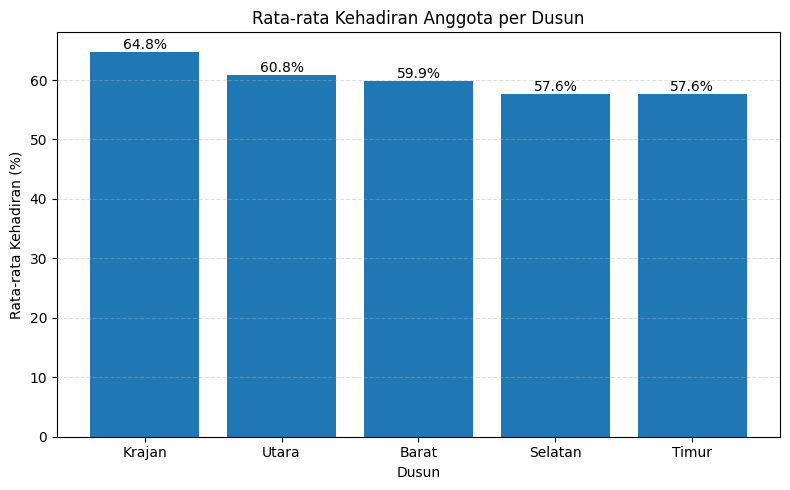


Ringkasan statistik:
             Usia  Kehadiran Kegiatan  Frekuensi Kegiatan  Jumlah Kegiatan
count  100.000000          100.000000           100.00000        100.00000
mean    22.490000           60.061000             6.40000          6.40000
std      3.526222           25.005421             3.39042          3.39042
min     17.000000            1.100000             1.00000          1.00000
25%     20.000000           40.000000             4.00000          4.00000
50%     22.000000           60.000000             6.00000          6.00000
75%     25.000000           80.000000             9.00000          9.00000
max     29.000000          100.000000            12.00000         12.00000


In [14]:
plt.figure(figsize=(8, 5))
bars = plt.bar(
    kehadiran_dusun.index,
    kehadiran_dusun.values
)

plt.title("Rata-rata Kehadiran Anggota per Dusun")
plt.xlabel("Dusun")
plt.ylabel("Rata-rata Kehadiran (%)")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# 10. MENAMPILKAN RINGKASAN STATISTIK
print("\nRingkasan statistik:")
print(df[[
    "Usia",
    "Kehadiran Kegiatan",
    "Frekuensi Kegiatan",
    "Jumlah Kegiatan"
]].describe())